# Notebook 04: Gradient Boosting & Second-Order Taylor XGBoost From Scratch

In this notebook we explore:
1. **Additive Functional Newton Boosting:** Training `XGBoostScratch` on a multi-frequency non-linear target function and watching how each shallow tree $f_t(x)$ is fitted to the current first-order gradients $g_i$ and second-order Hessians $h_i$ using the exact XGBoost leaf weight formula:
   $$w_j^* = -\frac{\sum_{i \in I_j} g_i}{\sum_{i \in I_j} h_i + \lambda}$$
2. **Sequential Residual Shrinkage Across Rounds $t \in \{1, 2, 5, 25\}$:** Visualizing the 2x4 progression of the ensemble curve $F_t(x) = \sum_{k=1}^t \eta f_k(x)$ (top row) alongside the shrinking Newton residuals $-g_i / h_i$ and next tree fit $f_{t+1}(x)$ (bottom row).
3. **Effect of $\lambda$ ($L_2$ Leaf Penalty) and $\gamma$ (Minimum Split Gain Complexity Penalty):** Demonstrating how structural regularization prevents overfitting in boosted ensembles.

In [1]:
import sys
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np

repo_root = Path.cwd()
if str(repo_root) not in sys.path:
    sys.path.insert(0, str(repo_root))

from src.plot_theme import (
    AMBER,
    CORAL,
    CYAN,
    EMERALD,
    PURPLE,
    SLATE_BLUE,
    TEXT_MUTED,
    apply_github_dark_style,
    save_fig,
)
from src.trees_engine import XGBoostScratch

apply_github_dark_style()

## 1. Training Second-Order XGBoost on a Complex Non-Linear Function

In [2]:
rng = np.random.default_rng(42)
m_xgb = 110
X_xgb = np.sort(rng.uniform(-2.5, 2.5, size=(m_xgb, 1)), axis=0)


def f_complex(x: np.ndarray) -> np.ndarray:
    return np.sin(2.0 * x) + 0.45 * np.cos(4.2 * x) - 0.15 * (x ** 2)


y_xgb = f_complex(X_xgb).ravel() + rng.normal(0.0, 0.22, size=m_xgb)
X_dense = np.linspace(-2.5, 2.5, 400).reshape(-1, 1)
y_dense_true = f_complex(X_dense).ravel()

# Train 25-tree XGBoost model with learning_rate=0.25, reg_lambda=1.0, max_depth=2
xgb_model = XGBoostScratch(
    n_estimators=25,
    learning_rate=0.25,
    max_depth=2,
    reg_lambda=1.0,
    gamma=0.01,
    loss="mse",
).fit(X_xgb, y_xgb)

print(f"XGBoost Initial MSE (Round 0): {np.mean((xgb_model.base_score_ - y_xgb)**2):.4f}")
print(f"XGBoost Final MSE (Round 25):   {np.mean((xgb_model.predict(X_xgb) - y_xgb)**2):.4f}")

XGBoost Initial MSE (Round 0): 0.7009
XGBoost Final MSE (Round 25):   0.0341


## 2. 2x4 Progression Dashboard: Additive Ensemble $F_t(x)$ vs Residual Tree Fits $f_t(x)$ (`05_xgboost_sequential_residual_fitting.png`)

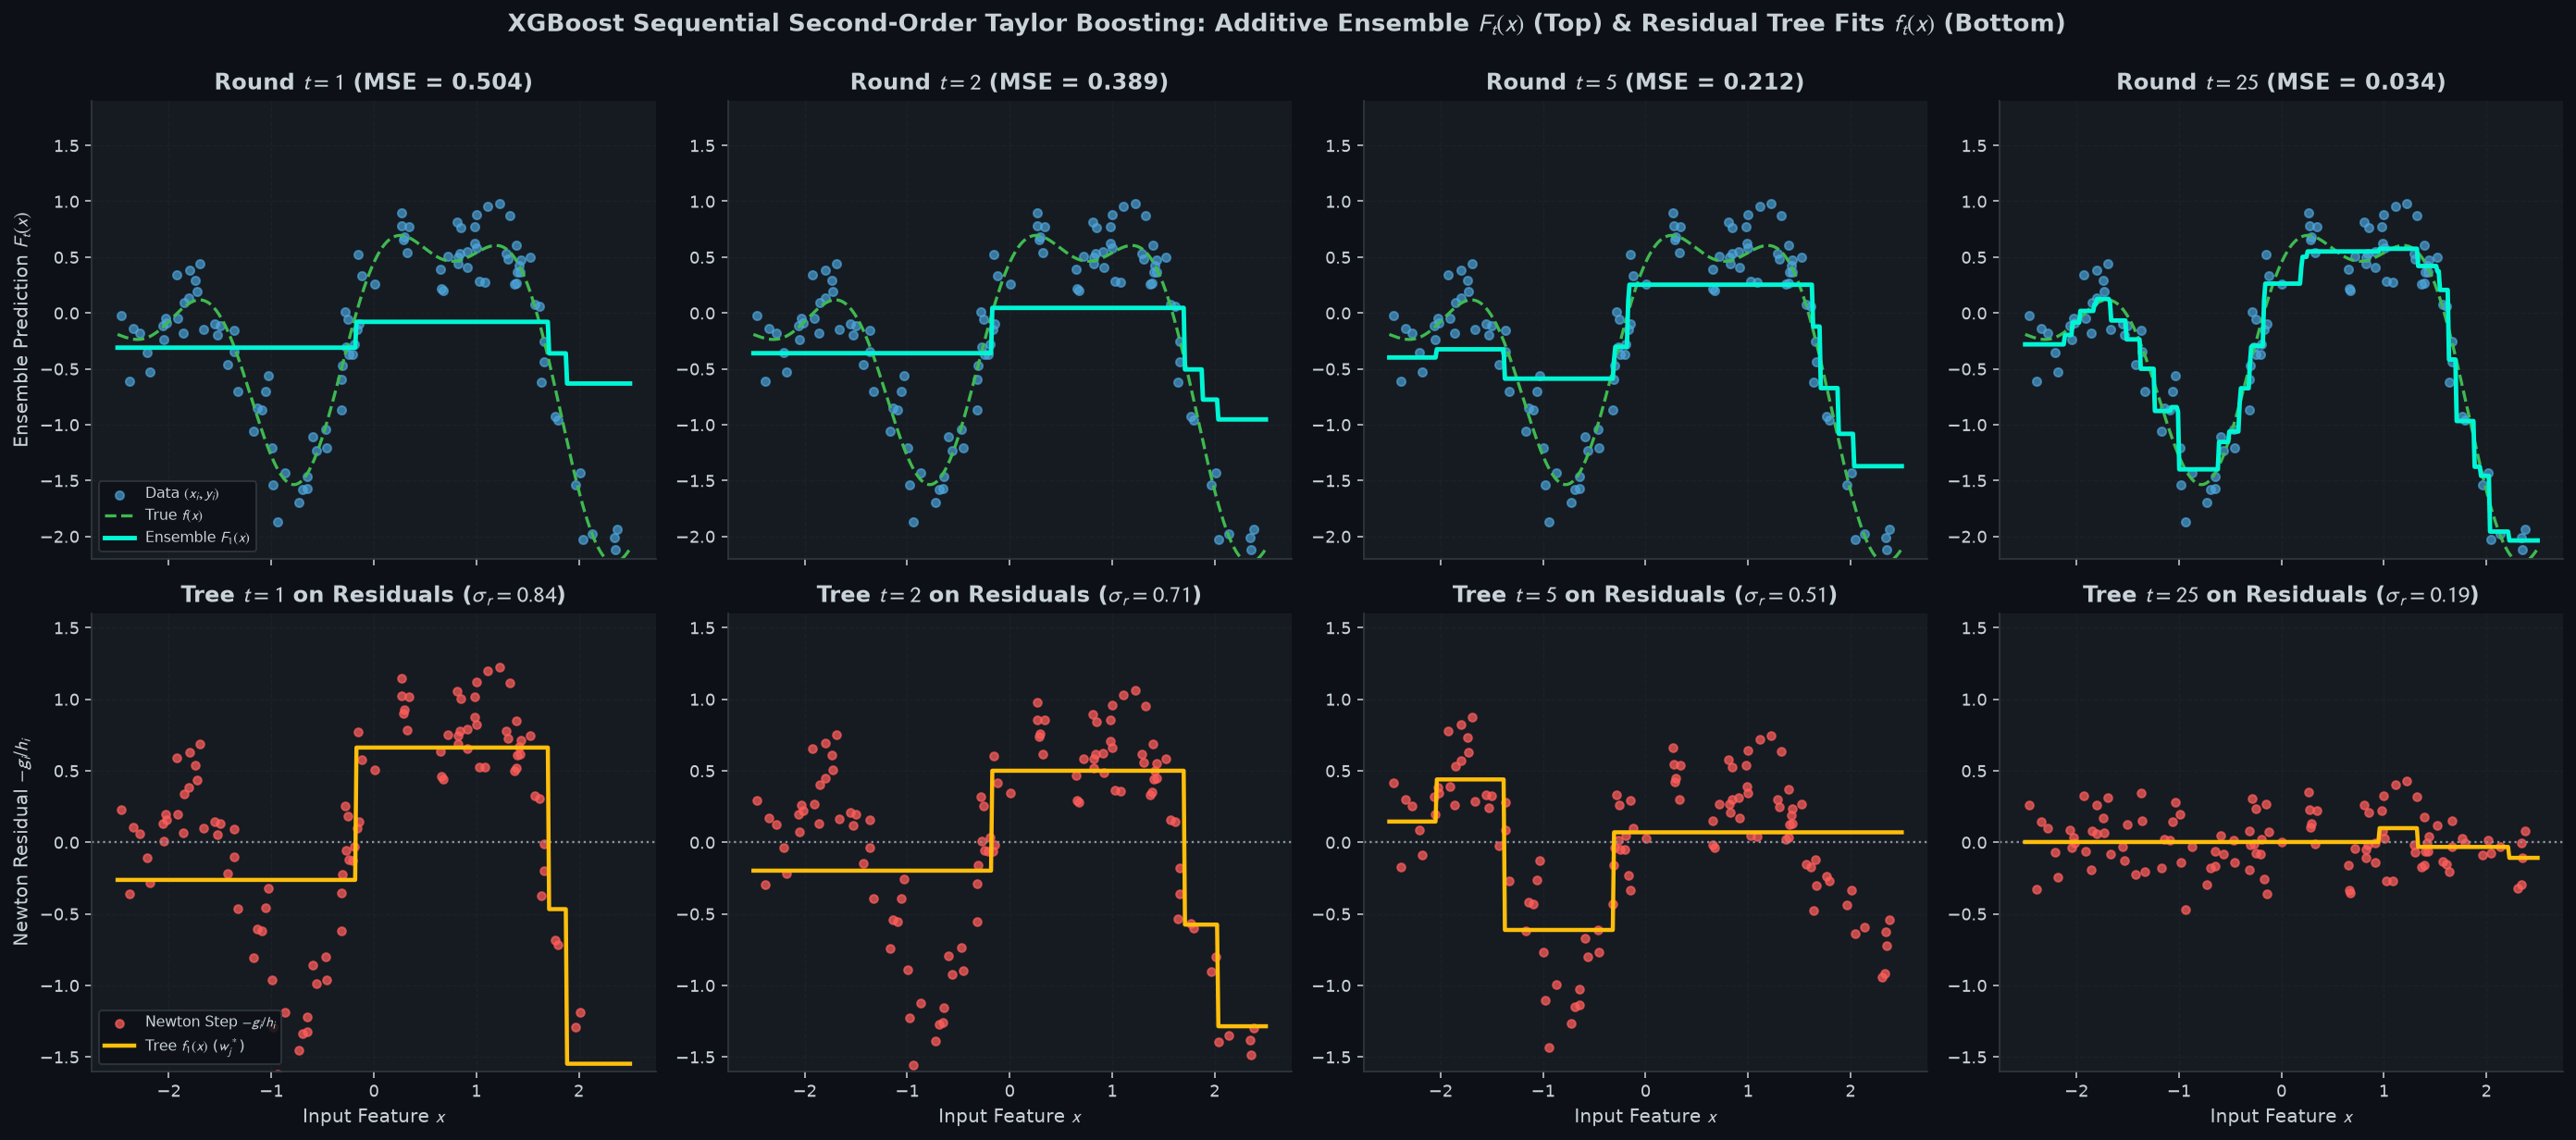

In [3]:
fig, axes = plt.subplots(2, 4, figsize=(20.0, 8.8), sharex=True)
rounds_to_plot = [1, 2, 5, 25]

for col_idx, t_round in enumerate(rounds_to_plot):
    ax_top = axes[0, col_idx]
    ax_bot = axes[1, col_idx]

    # Top row: Cumulative ensemble prediction F_t(x) after t_round trees
    F_t_train = xgb_model.predict(X_xgb, up_to_tree=t_round)
    F_t_dense = xgb_model.predict(X_dense, up_to_tree=t_round)
    mse_t = float(np.mean((F_t_train - y_xgb) ** 2))

    ax_top.scatter(X_xgb[:, 0], y_xgb, color=SLATE_BLUE, s=22, alpha=0.65, label="Data $(x_i, y_i)$")
    ax_top.plot(X_dense[:, 0], y_dense_true, color=EMERALD, linestyle="--", linewidth=1.7, label="True $f(x)$")
    ax_top.plot(X_dense[:, 0], F_t_dense, color=CYAN, linewidth=2.5, label=f"Ensemble $F_{{{t_round}}}(x)$")
    ax_top.set_ylim(-2.2, 1.9)
    ax_top.set_title(f"Round $t = {t_round}$ (MSE = {mse_t:.3f})")
    if col_idx == 0:
        ax_top.set_ylabel("Ensemble Prediction $F_t(x)$")
        ax_top.legend(loc="lower left", fontsize=8.0)

    # Bottom row: Pseudo-residuals -g_i / h_i = y_i - F_{t-1}(x_i) and the t-th tree f_t(x) fitted to them
    F_prev_train = xgb_model.predict(X_xgb, up_to_tree=t_round - 1)
    _, g_t, h_t = xgb_model.compute_loss_grad_hess(y_xgb, F_prev_train)
    newton_res = -g_t / h_t  # Target for tree t_round
    tree_t_pred = xgb_model._predict_tree(X_dense, xgb_model.trees_[t_round - 1])

    ax_bot.axhline(0.0, color=TEXT_MUTED, linestyle=":", linewidth=1.2)
    ax_bot.scatter(X_xgb[:, 0], newton_res, color=CORAL, s=20, alpha=0.72, label=r"Newton Step $-g_i / h_i$")
    ax_bot.plot(X_dense[:, 0], tree_t_pred, color=AMBER, linewidth=2.3, label=f"Tree $f_{{{t_round}}}(x)$ ($w_j^*$)")
    ax_bot.set_ylim(-1.6, 1.6)
    ax_bot.set_xlabel("Input Feature $x$")
    ax_bot.set_title(fr"Tree $t={t_round}$ on Residuals ($\sigma_r={np.std(newton_res):.2f}$)")
    if col_idx == 0:
        ax_bot.set_ylabel("Newton Residual $-g_i / h_i$")
        ax_bot.legend(loc="lower left", fontsize=8.0)

fig.suptitle(
    "XGBoost Sequential Second-Order Taylor Boosting: Additive Ensemble $F_t(x)$ (Top) & Residual Tree Fits $f_t(x)$ (Bottom)",
    fontsize=13.5,
    fontweight="bold",
    y=0.995,
)
fig.tight_layout()
assets_dir = Path("assets")
assets_dir.mkdir(parents=True, exist_ok=True)
save_fig(fig, assets_dir / "05_xgboost_sequential_residual_fitting.png")
plt.show()

## 3. Second-Order Log-Loss Classification with XGBoost ($g_i = p_i - y_i, \; h_i = p_i(1 - p_i)$)

In [4]:
theta_c = rng.uniform(0, 2 * np.pi, 160)
r_c = np.concatenate([rng.normal(0.55, 0.12, 80), rng.normal(1.45, 0.14, 80)])
X_ring_xgb = np.column_stack([r_c * np.cos(theta_c), r_c * np.sin(theta_c)])
y_ring_xgb = np.concatenate([np.zeros(80), np.ones(80)])

xgb_clf = XGBoostScratch(
    n_estimators=35,
    learning_rate=0.35,
    max_depth=3,
    reg_lambda=1.0,
    gamma=0.05,
    loss="logloss",
).fit(X_ring_xgb, y_ring_xgb)

acc_xgb_clf = float(np.mean(xgb_clf.predict(X_ring_xgb) == y_ring_xgb))
print(f"XGBoost Log-Loss Classifier (h_i = p_i(1-p_i)) Training Accuracy: {acc_xgb_clf*100:.2f}% | Final Log-Loss: {xgb_clf.loss_history[-1]:.4f}")

XGBoost Log-Loss Classifier (h_i = p_i(1-p_i)) Training Accuracy: 100.00% | Final Log-Loss: 0.0143
